# Parallel TLP Benchmark

This notebook runs TLP benchmarks across T=1 to T=100 using 6 parallel threads.
Each thread processes batches of 10 T values and saves results incrementally.

In [31]:
import json
import time
import numpy as np
from qiskit import QuantumCircuit
import secrets
from concurrent.futures import ThreadPoolExecutor, as_completed  # ThreadPoolExecutor works in notebooks
from queue import Queue
import threading
from pathlib import Path
import glob
import gc  # For explicit garbage collection

from pv_cvqc import PV_CVQC

## Function to Process a Batch of T Values

## Performance Diagnostics (Optional)

Run this cell to check detailed timing breakdown for a single T value.

In [ ]:
def diagnostic_run(T=10, trials=3):
    """
    Run detailed diagnostics to identify timing bottlenecks.
    """
    import time
    from qiskit import QuantumCircuit
    from pv_cvqc import PV_CVQC
    
    print(f"Running diagnostic for T={T} with {trials} trials\n")
    print("="*60)
    
    circuit = QuantumCircuit(2)
    circuit.h(0)
    circuit.cx(0, 1)
    
    secp = 256
    
    for trial in range(trials):
        print(f"\nTrial {trial + 1}:")
        print("-" * 40)
        
        protocol = PV_CVQC()
        
        # Time individual components
        t0 = time.perf_counter()
        from cvqc_protocol.hamiltonian_compiler import HamiltonianCompiler
        compiler = HamiltonianCompiler(circuit)
        hist_circuit = compiler.compile()
        t1 = time.perf_counter()
        print(f"  Circuit compilation:  {(t1-t0)*1000:.2f}ms")
        
        t0 = time.perf_counter()
        from timelock_puzzle.tlp_garbling import PythonGarbledTLP
        tlp = PythonGarbledTLP(T=T)
        t1 = time.perf_counter()
        print(f"  TLP initialization:   {(t1-t0)*1000:.2f}ms")
        
        t0 = time.perf_counter()
        pp = tlp.PSetup_Garble()
        t1 = time.perf_counter()
        print(f"  PSetup_Garble:        {(t1-t0)*1000:.2f}ms  ← GARBLING")
        
        t0 = time.perf_counter()
        from cvqc_protocol.ccy_protocol import Verifier
        ccy_verifier = Verifier()
        pk, sk = ccy_verifier.round1(hist_circuit, Q=16)
        t1 = time.perf_counter()
        print(f"  CCY round1:           {(t1-t0)*1000:.2f}ms")
        
        t0 = time.perf_counter()
        import secrets
        from utils import random_oracle
        r = secrets.token_bytes(secp // 8)
        d = random_oracle(str(sk["s"]) + str(int.from_bytes(r, "big")), secp // 8)
        t1 = time.perf_counter()
        print(f"  Random oracle:        {(t1-t0)*1000:.2f}ms")
        
        t0 = time.perf_counter()
        puzzle = tlp.PGen(sk["s"], pp)
        t1 = time.perf_counter()
        print(f"  PGen (puzzle gen):    {(t1-t0)*1000:.2f}ms")
        
        t0 = time.perf_counter()
        y = tlp.PSolve(puzzle, pp)
        t1 = time.perf_counter()
        print(f"  PSolve (reveal):      {(t1-t0)*1000:.2f}ms")
    
    print("\n" + "="*60)
    print("Diagnostic complete\n")

# Uncomment to run diagnostics:
diagnostic_run(T=3, trials=10)

In [32]:
def run_batch(T_batch, trials=5, secp=256):
    """
    Run benchmark for a batch of T values.
    
    Args:
        T_batch: List of T values to test
        trials: Number of trials per T value
        secp: Security parameter
    
    Returns:
        Dictionary with results for this batch
    """
    thread_id = threading.current_thread().name
    print(f"[{thread_id}] Starting batch: T={T_batch[0]} to T={T_batch[-1]}")
    
    # Create test circuit
    circuit = QuantumCircuit(2)
    circuit.h(0)
    circuit.cx(0, 1)
    
    batch_results = {
        'T_min': T_batch[0],
        'T_max': T_batch[-1],
        'trials': trials,
        'results': []
    }
    
    for T in T_batch:
        print(f"[{thread_id}] Testing T={T}...", end=" ", flush=True)
        
        T_results = {
            'T': T,
            'trial_data': []
        }
        
        # Add warmup run (not counted in results) to stabilize timing
        if trials > 0:
            try:
                warmup_protocol = PV_CVQC()
                warmup_crs, warmup_sk = warmup_protocol.setup(secp, circuit, testing_T=T)
                del warmup_protocol, warmup_crs, warmup_sk
                gc.collect()
            except:
                pass
        
        for trial in range(trials):
            # Force garbage collection before each trial for consistency
            gc.collect()
            
            try:
                # Create new protocol instance for each trial
                protocol = PV_CVQC()
                
                # Setup phase (with testing_T parameter)
                crs, sk = protocol.setup(secp, circuit, testing_T=T)
                
                # Prove phase
                proof = protocol.prove(crs, circuit)
                
                # Reveal phase
                y = protocol.reveal(crs, circuit)
                
                # Verify phase
                result = protocol.verify(crs, proof, y)
                
                # Store all timing data for this trial
                T_results['trial_data'].append({
                    'trial_num': trial + 1,
                    'setup_time': protocol.setup_time,
                    'garbling_time': protocol.garbling_time,
                    'generation_time': protocol.generation_time,
                    'prove_time': protocol.prove_time,
                    'reveal_time': protocol.reveal_time,
                    'verify_time': protocol.verify_time,
                    'total_time': protocol.setup_time + protocol.prove_time + protocol.reveal_time + protocol.verify_time,
                    'verification_passed': result
                })
                
                # Clean up to reduce memory pressure
                del protocol, crs, sk, proof, y, result
                
                print(".", end="", flush=True)
                
            except Exception as e:
                print(f"\n[{thread_id}] Error in trial {trial+1} for T={T}: {e}")
                gc.collect()
                continue
        
        if T_results['trial_data']:
            batch_results['results'].append(T_results)
            print(f" Done! ({len(T_results['trial_data'])} trials completed)")
        else:
            print(" Failed!")
        
        # Clean up after each T value
        gc.collect()
    
    # Save batch results to JSON
    filename = f"tlp_benchmark_{T_batch[0]}_{T_batch[-1]}.json"
    with open(filename, 'w') as f:
        json.dump(batch_results, f, indent=2)
    
    print(f"[{thread_id}] Batch complete. Saved to {filename}")
    return batch_results

## Run Parallel Benchmark

In [33]:
def run_parallel_benchmark(T_min=1, T_max=100, batch_size=10, num_workers=3, trials=5):
    """
    Run benchmark in parallel across multiple threads.
    
    Note: Uses ThreadPoolExecutor (not ProcessPoolExecutor) because Jupyter notebooks
    can't pickle functions for multiprocessing. For true process-based parallelization,
    create a standalone .py script.
    
    Args:
        T_min: Minimum T value
        T_max: Maximum T value
        batch_size: Number of T values per batch
        num_workers: Number of parallel threads (reduced default to 3 for less contention)
        trials: Number of trials per T value
    """
    print("="*60)
    print("PARALLEL TLP BENCHMARK (Thread-based)")
    print("="*60)
    print(f"T range: {T_min} to {T_max}")
    print(f"Batch size: {batch_size}")
    print(f"Worker threads: {num_workers}")
    print(f"Trials per T: {trials}")
    print(f"Note: Using threads due to Jupyter limitations")
    print("="*60)
    
    # Create batches
    all_T_values = list(range(T_min, T_max + 1))
    batches = [all_T_values[i:i + batch_size] for i in range(0, len(all_T_values), batch_size)]
    
    print(f"\nCreated {len(batches)} batches")
    print(f"Starting parallel execution...\n")
    
    start_time = time.time()
    
    # Run batches in parallel using ThreadPoolExecutor
    all_results = []
    with ThreadPoolExecutor(max_workers=num_workers, thread_name_prefix="Worker") as executor:
        # Submit all batches
        future_to_batch = {executor.submit(run_batch, batch, trials): batch for batch in batches}
        
        # Collect results as they complete
        for future in as_completed(future_to_batch):
            batch = future_to_batch[future]
            try:
                result = future.result()
                all_results.append(result)
            except Exception as e:
                print(f"Batch {batch[0]}-{batch[-1]} generated an exception: {e}")
    
    total_time = time.time() - start_time
    
    print("\n" + "="*60)
    print("BENCHMARK COMPLETE")
    print("="*60)
    print(f"Total execution time: {total_time:.2f}s")
    print(f"Results saved to {len(all_results)} JSON files")
    print("="*60)
    
    return all_results

## Execute the Benchmark

Run this cell to start the parallel benchmark. This will test T=1 to T=100 with 5 trials each.

## Alternative: Sequential Benchmark (for comparison)

Use this if parallel results are too noisy. Sequential execution avoids resource contention.

**Note on parallelization:** Jupyter notebooks can't use `ProcessPoolExecutor` (true multiprocessing) due to pickling limitations. The parallel version above uses threads, which may still show some stochastic behavior due to Python's GIL. For the most consistent results:
- Use the **sequential benchmark** below, OR
- Export this code to a standalone `.py` script to use `ProcessPoolExecutor`

In [34]:
def run_sequential_benchmark(T_min=1, T_max=100, batch_size=10, trials=5):
    """
    Run benchmark sequentially (no parallelization).
    More consistent results but slower execution.
    """
    print("="*60)
    print("SEQUENTIAL TLP BENCHMARK")
    print("="*60)
    print(f"T range: {T_min} to {T_max}")
    print(f"Batch size: {batch_size}")
    print(f"Trials per T: {trials}")
    print("="*60)
    
    # Create batches
    all_T_values = list(range(T_min, T_max + 1))
    batches = [all_T_values[i:i + batch_size] for i in range(0, len(all_T_values), batch_size)]
    
    print(f"\nCreated {len(batches)} batches")
    print(f"Starting sequential execution...\n")
    
    start_time = time.time()
    
    all_results = []
    for batch in batches:
        result = run_batch(batch, trials)
        all_results.append(result)
    
    total_time = time.time() - start_time
    
    print("\n" + "="*60)
    print("BENCHMARK COMPLETE")
    print("="*60)
    print(f"Total execution time: {total_time:.2f}s")
    print(f"Results saved to {len(all_results)} JSON files")
    print("="*60)
    
    return all_results

# Uncomment to run sequential benchmark instead:
# results = run_sequential_benchmark(T_min=1, T_max=20, batch_size=10, trials=5)

In [ ]:
results = run_sequential_benchmark(T_min=2, T_max=5, batch_size=1, trials=5)

In [49]:
# Run the parallel benchmark
# Using fewer workers (3) to reduce thread contention and stochastic behavior
results = run_parallel_benchmark(T_min=12, T_max=12, batch_size=1, num_workers=4, trials=3)

PARALLEL TLP BENCHMARK (Thread-based)
T range: 12 to 12
Batch size: 1
Worker threads: 4
Trials per T: 3
Note: Using threads due to Jupyter limitations

Created 1 batches
Starting parallel execution...

[Worker_0] Starting batch: T=12 to T=12
[Worker_0] Testing T=12... In Compiler - Input Circuit Depth: 2
In Compiler - Required Clock Qubits: 2
In Compiler - Decomposing to basis gates...
[Setup] Using testing T = 12 for TLP
[Timer] Garbling setup: 18.1830s
(Config) -- Circuit Size: 4 qubits
(Config) -- LWE Parameters: N=2, Q=16 (4 bits/int)
(Config) -- Total Capacity: 8 bits
(V1) -- Generated LWE Keys (Q=16)
   > Trapdoor s: [12  8]
[Timer] Puzzle generation: 0.0001s
[Timer] Total setup: 18.1891s
In Compiler - Input Circuit Depth: 2
In Compiler - Required Clock Qubits: 2
In Compiler - Decomposing to basis gates...
[Setup] Using testing T = 12 for TLP
[Timer] Garbling setup: 18.9779s
(Config) -- Circuit Size: 4 qubits
(Config) -- LWE Parameters: N=2, Q=16 (4 bits/int)
(Config) -- Total Ca

## Aggregate and Plot Results

This cell reads all the JSON files and creates plots showing average times for each T value.

Loading benchmark results...
Found 14 result files (out of 16 matching pattern)
Loaded data for 13 T values


Generating plots...

✓ Plot saved to tlp_protocol_phases.png


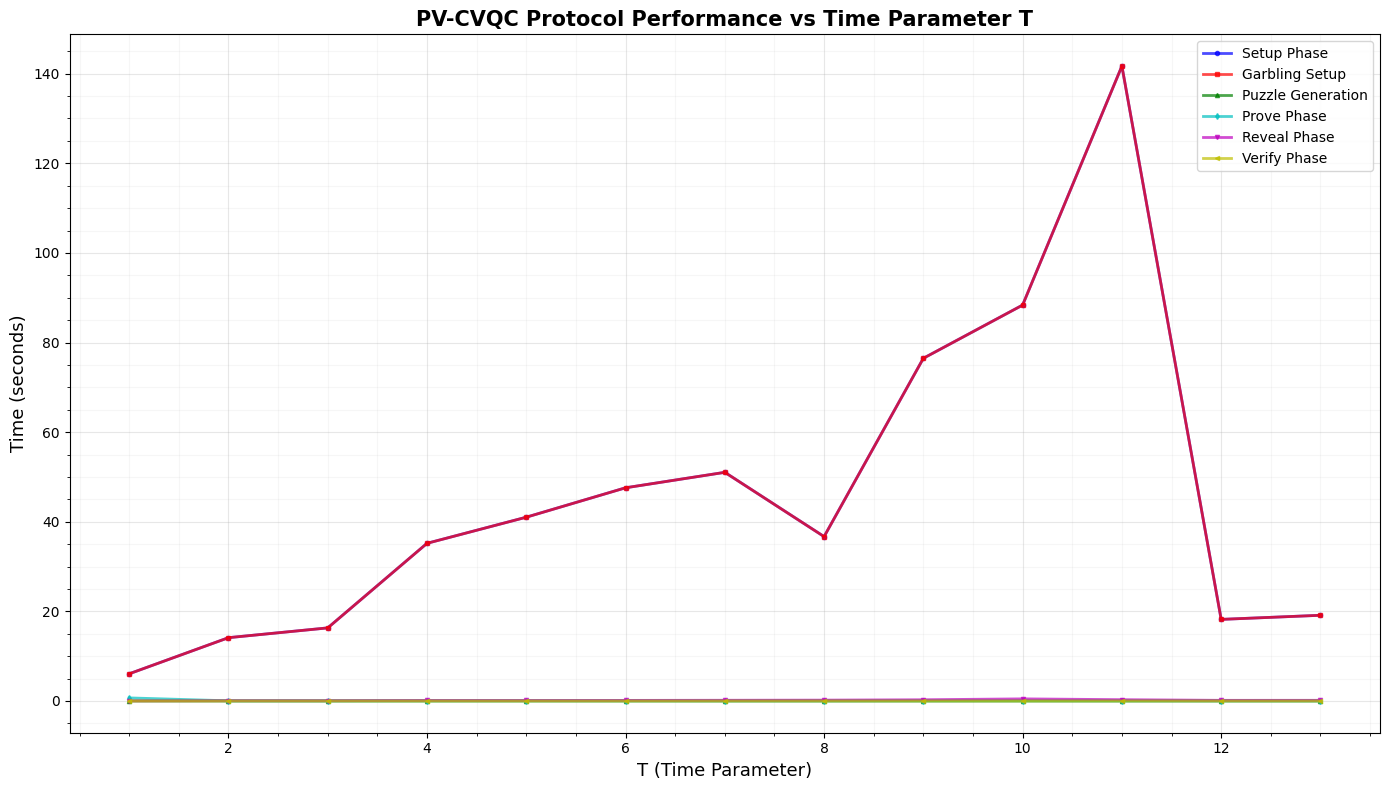

✓ Plot saved to tlp_key_phases.png


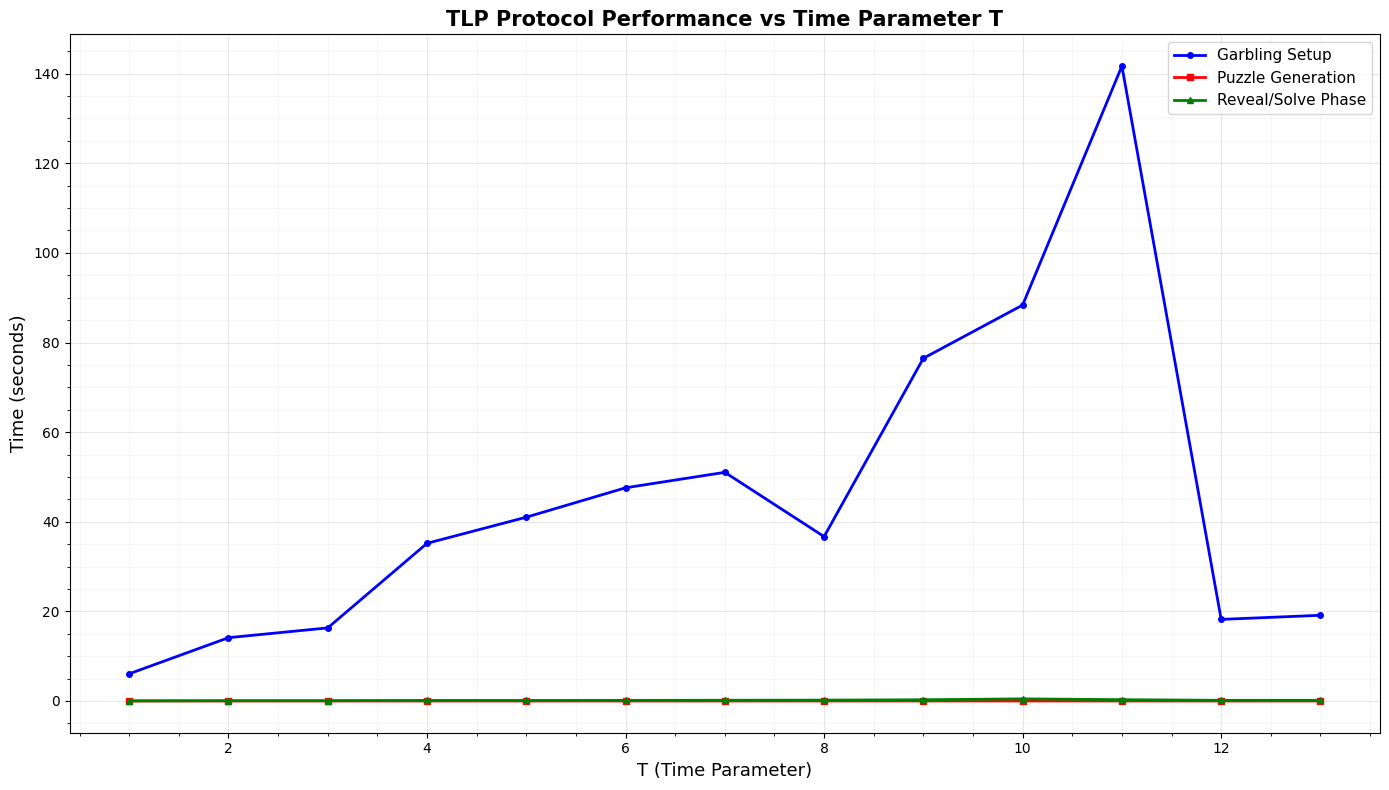

✓ Plot saved to tlp_solve_generation.png


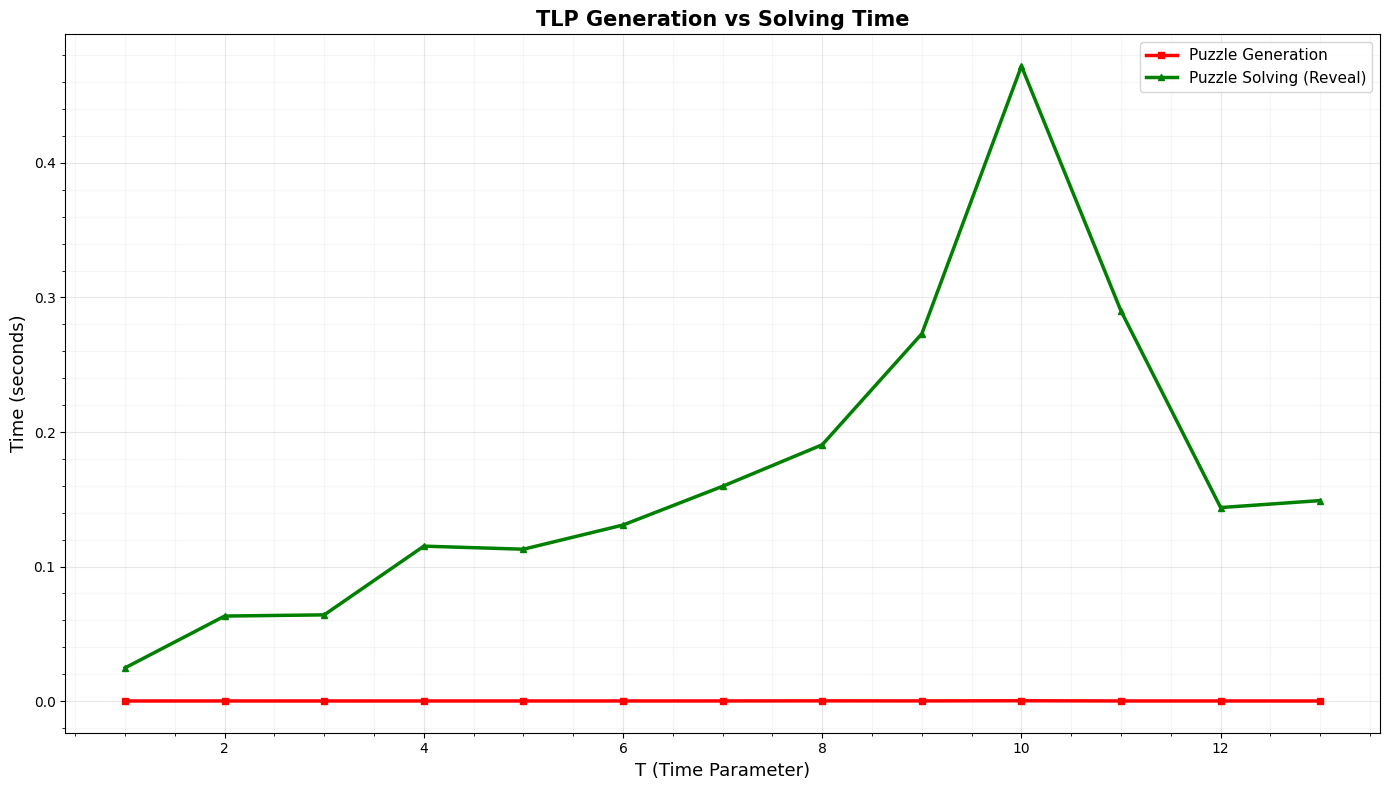


✓ All plots generated successfully!


In [50]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
import glob
import json
import numpy as np
from pathlib import Path
import re

def load_all_results(pattern="tlp_benchmark_*.json"):
    """
    Load all benchmark JSON files and aggregate results.
    
    Returns:
        Dictionary with T values as keys and timing data as values
    """
    json_files = glob.glob(pattern)
    
    # Filter to only include files with the format: tlp_benchmark_<number>_<number>.json
    # This excludes old format files like tlp_benchmark_results.json
    filtered_files = [f for f in json_files if re.match(r'tlp_benchmark_\d+_\d+\.json', f)]
    
    print(f"Found {len(filtered_files)} result files (out of {len(json_files)} matching pattern)")
    
    aggregated = {}
    
    for json_file in filtered_files:
        try:
            with open(json_file, 'r') as f:
                data = json.load(f)
            
            # Verify the file has the expected structure
            if 'results' not in data:
                print(f"⚠ Skipping {json_file}: missing 'results' key")
                continue
            
            # Process each T value in this batch
            for T_result in data['results']:
                T = T_result['T']
                trials = T_result['trial_data']
                
                if T not in aggregated:
                    aggregated[T] = {
                        'setup_times': [],
                        'garbling_times': [],
                        'generation_times': [],
                        'prove_times': [],
                        'reveal_times': [],
                        'verify_times': [],
                        'total_times': []
                    }
                
                # Collect all trial data
                for trial in trials:
                    aggregated[T]['setup_times'].append(trial['setup_time'])
                    aggregated[T]['garbling_times'].append(trial['garbling_time'])
                    aggregated[T]['generation_times'].append(trial['generation_time'])
                    aggregated[T]['prove_times'].append(trial['prove_time'])
                    aggregated[T]['reveal_times'].append(trial['reveal_time'])
                    aggregated[T]['verify_times'].append(trial['verify_time'])
                    aggregated[T]['total_times'].append(trial['total_time'])
        
        except Exception as e:
            print(f"⚠ Error loading {json_file}: {e}")
            continue
    
    return aggregated


def compute_averages(aggregated):
    """
    Compute average times for each T value.
    """
    T_values = sorted(aggregated.keys())
    
    avg_data = {
        'T_values': T_values,
        'avg_setup': [],
        'avg_garbling': [],
        'avg_generation': [],
        'avg_prove': [],
        'avg_reveal': [],
        'avg_verify': [],
        'avg_total': []
    }
    
    for T in T_values:
        avg_data['avg_setup'].append(np.mean(aggregated[T]['setup_times']))
        avg_data['avg_garbling'].append(np.mean(aggregated[T]['garbling_times']))
        avg_data['avg_generation'].append(np.mean(aggregated[T]['generation_times']))
        avg_data['avg_prove'].append(np.mean(aggregated[T]['prove_times']))
        avg_data['avg_reveal'].append(np.mean(aggregated[T]['reveal_times']))
        avg_data['avg_verify'].append(np.mean(aggregated[T]['verify_times']))
        avg_data['avg_total'].append(np.mean(aggregated[T]['total_times']))
    
    return avg_data


def plot_protocol_phases(avg_data, filename='tlp_protocol_phases.png'):
    """
    Plot all protocol phases on one graph.
    """
    plt.figure(figsize=(14, 8))
    
    T_values = avg_data['T_values']
    
    # Plot all phases
    plt.plot(T_values, avg_data['avg_setup'], 'b-o', 
             label='Setup Phase', linewidth=2, markersize=3, alpha=0.7)
    plt.plot(T_values, avg_data['avg_garbling'], 'r-s', 
             label='Garbling Setup', linewidth=2, markersize=3, alpha=0.7)
    plt.plot(T_values, avg_data['avg_generation'], 'g-^', 
             label='Puzzle Generation', linewidth=2, markersize=3, alpha=0.7)
    plt.plot(T_values, avg_data['avg_prove'], 'c-d', 
             label='Prove Phase', linewidth=2, markersize=3, alpha=0.7)
    plt.plot(T_values, avg_data['avg_reveal'], 'm-v', 
             label='Reveal Phase', linewidth=2, markersize=3, alpha=0.7)
    plt.plot(T_values, avg_data['avg_verify'], 'y-<', 
             label='Verify Phase', linewidth=2, markersize=3, alpha=0.7)
    # plt.plot(T_values, avg_data['avg_total'], 'k->', 
    #          label='Total Time', linewidth=2.5, markersize=3, alpha=0.9)
    
    plt.xlabel('T (Time Parameter)', fontsize=13)
    plt.ylabel('Time (seconds)', fontsize=13)
    plt.title('PV-CVQC Protocol Performance vs Time Parameter T', fontsize=15, fontweight='bold')
    plt.legend(fontsize=10, loc='best')
    plt.grid(True, alpha=0.3)
    plt.grid(True, which='minor', alpha=0.1)
    plt.minorticks_on()
    
    # Force x-axis to show only integer values
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"✓ Plot saved to {filename}")
    plt.show()


def plot_key_phases(avg_data, filename='tlp_key_phases.png'):
    """
    Plot the three key TLP-related phases (matching original benchmark).
    """
    plt.figure(figsize=(14, 8))
    
    T_values = avg_data['T_values']
    
    # Plot three key lines (matching original benchmark)
    plt.plot(T_values, avg_data['avg_garbling'], 'b-o', 
             label='Garbling Setup', linewidth=2, markersize=4)
    plt.plot(T_values, avg_data['avg_generation'], 'r-s', 
             label='Puzzle Generation', linewidth=2, markersize=4)
    plt.plot(T_values, avg_data['avg_reveal'], 'g-^', 
             label='Reveal/Solve Phase', linewidth=2, markersize=4)
    
    plt.xlabel('T (Time Parameter)', fontsize=13)
    plt.ylabel('Time (seconds)', fontsize=13)
    plt.title('TLP Protocol Performance vs Time Parameter T', fontsize=15, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.grid(True, which='minor', alpha=0.1)
    plt.minorticks_on()
    
    # Force x-axis to show only integer values
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"✓ Plot saved to {filename}")
    plt.show()


def plot_solve_generation(avg_data, filename='tlp_solve_generation.png'):
    """
    Plot just the solving (reveal) and generation times.
    """
    plt.figure(figsize=(14, 8))
    
    T_values = avg_data['T_values']
    
    # Plot only generation and solving times
    plt.plot(T_values, avg_data['avg_generation'], 'r-s', 
             label='Puzzle Generation', linewidth=2.5, markersize=5)
    plt.plot(T_values, avg_data['avg_reveal'], 'g-^', 
             label='Puzzle Solving (Reveal)', linewidth=2.5, markersize=5)
    
    plt.xlabel('T (Time Parameter)', fontsize=13)
    plt.ylabel('Time (seconds)', fontsize=13)
    plt.title('TLP Generation vs Solving Time', fontsize=15, fontweight='bold')
    plt.legend(fontsize=11)
    plt.grid(True, alpha=0.3)
    plt.grid(True, which='minor', alpha=0.1)
    plt.minorticks_on()
    
    # Force x-axis to show only integer values
    ax = plt.gca()
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    
    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches='tight')
    print(f"✓ Plot saved to {filename}")
    plt.show()


# Load and aggregate all results
print("Loading benchmark results...")
aggregated = load_all_results()
print(f"Loaded data for {len(aggregated)} T values\n")

# Compute averages
avg_data = compute_averages(aggregated)

# Generate plots
print("\nGenerating plots...\n")
plot_protocol_phases(avg_data)
plot_key_phases(avg_data)
plot_solve_generation(avg_data)

print("\n✓ All plots generated successfully!")